In [88]:
import mysql.connector
import pandas as pd
from sqlalchemy import create_engine
import os
from pathlib import Path

In [89]:
base_folder = Path(r"/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp")
output_file = base_folder / "combined_skull_analysis.xlsx"

In [90]:
# Defining your SQL query
conn = mysql.connector.connect(option_files=os.path.expanduser('~/.my.cnf')) 

sql_query = """
SELECT o.SPECIMEN_ID, s.STRAIN, s.GENDER, e.DATE, m.COHORT_ID,  o.VALUE_CATEGORY
FROM OBSERVATION as o, MOUSE as m, SPECIMEN as s, EXPERIMENT as e, PARAMETER as p
WHERE o.SPECIMEN_ID=m.ID and m.ID=s.ID and e.ID=o.EXPERIMENT_ID and o.PARAMETER_STABLE_ID=p.PARAMETER_STABLE_ID
 and m.COHORT_ID like 'c%' and o.PARAMETER_STABLE_ID='CCP_XRY_001_001'
"""
sql_query = """
SELECT o.SPECIMEN_ID,s.STRAIN,s.GENDER, m.COHORT_ID, e.DATE,o.VALUE_CATEGORY as SkullShape, LEN.VALUE_DATA_POINT as CraniumLength,COM.VALUE_TEXT as Comment
FROM OBSERVATION as o
    INNER JOIN MOUSE as m ON o.SPECIMEN_ID = m.ID
    INNER JOIN SPECIMEN as s ON m.ID = s.ID
    INNER JOIN EXPERIMENT as e ON e.ID = o.EXPERIMENT_ID
    INNER JOIN PARAMETER as p ON o.PARAMETER_STABLE_ID = p.PARAMETER_STABLE_ID
    LEFT JOIN (
        SELECT SPECIMEN_ID, VALUE_TEXT
        FROM OBSERVATION
        WHERE PARAMETER_STABLE_ID = 'CCP_XRY_032_001'
    ) AS COM ON o.SPECIMEN_ID = COM.SPECIMEN_ID

    LEFT JOIN (
        SELECT SPECIMEN_ID, VALUE_DATA_POINT
        FROM OBSERVATION
        WHERE PARAMETER_STABLE_ID = 'CCP_XRY_893_001'
    ) AS LEN ON o.SPECIMEN_ID = LEN.SPECIMEN_ID
WHERE
    m.COHORT_ID LIKE 'c%'
    AND o.PARAMETER_STABLE_ID = 'CCP_XRY_001_001';
"""
# Reading data into a Pandas DataFrame
db_df = pd.read_sql(sql_query, conn)

# Closing the connection
conn.close()

# Displaying the DataFrame


/tmp/ipykernel_2688066/1546436508.py:33: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  db_df = pd.read_sql(sql_query, conn)


In [91]:
def file_analysis_f(db_cohorts,cohort_df):
    
    res = []
    indexes= []
    for subj in cohort_df.index:
        try:
            specimen_name = subj.split("_")[2]
            # if 'SuturesOpen' not in ColumnNames set it to None
            
            
            abn_df = dict(db_cohorts[(db_cohorts['SPECIMEN_ID'] == specimen_name)][['GENDER','STRAIN','COHORT_ID','DATE','CraniumLength','SkullShape','Comment']].iloc[0])
            indexes.append(subj )
            #print(abn_df)
            abn_df.update(dict(cohort_df.loc[subj]))
            res.append(abn_df)
            
        except Exception as e:
            #print(e)
            pass
    return res,indexes

indexes = []
data = []
for fold_ in base_folder.iterdir():
    if fold_.is_file():
        continue
    file_ = (fold_/"abnormality_automated_combined.csv")
    
    if not file_.exists():
        continue
    #print("q")
    file_analysis = pd.read_csv(file_,index_col=0)
    #print(file_analysis)
    td, ind = file_analysis_f(db_df,file_analysis)
    #print(td)
    indexes+= ind
    data+=td
    
    
    
    
    
    

In [92]:
res_df = pd.DataFrame(data,index=indexes)

In [93]:

res_df.to_excel(output_file)

#res_df.to_csv(output_file)

In [94]:
# analyse db_df


db_df['SutureOpen'] = db_df['Comment'].apply(lambda x: 'suture' in x.lower() if x is not None else False)
db_df['SutureOpen'].value_counts()
db_df = db_df.drop_duplicates()

<AxesSubplot: xlabel='COHORT_ID'>

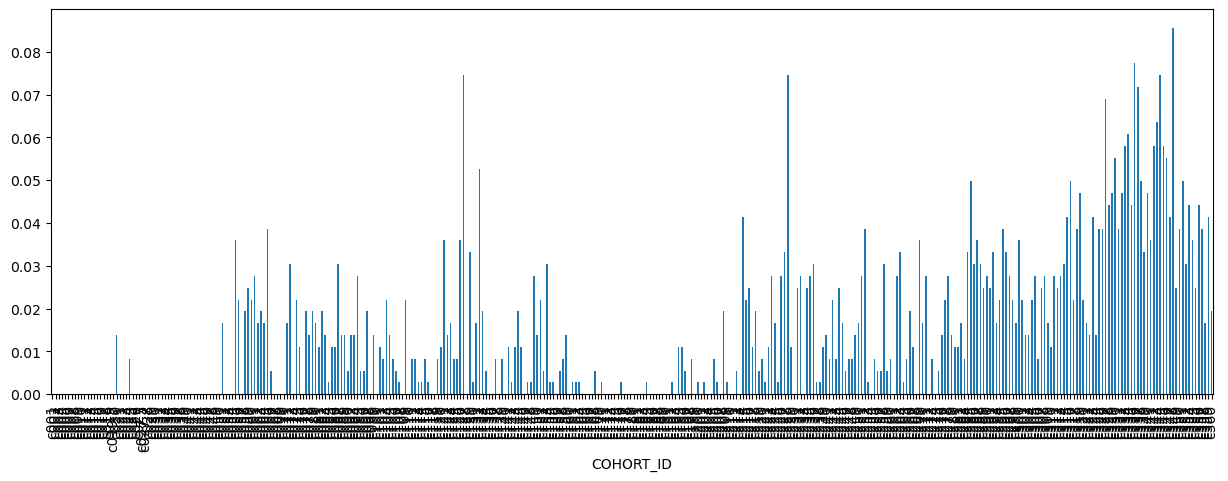

In [95]:
# divide by cohort
cohort_df = db_df.groupby('COHORT_ID').count()
# analyse ratio of SutureOpen in each cohort
cohort_df['SutureOpen'] = db_df.groupby('COHORT_ID')['SutureOpen'].sum()
cohort_df['SutureOpenRatio'] = cohort_df['SutureOpen']/cohort_df['SutureOpen'].count()

# plot the ratio
cohort_df['SutureOpenRatio'].plot.bar(figsize=(15,5))


<AxesSubplot: xlabel='COHORT_ID'>

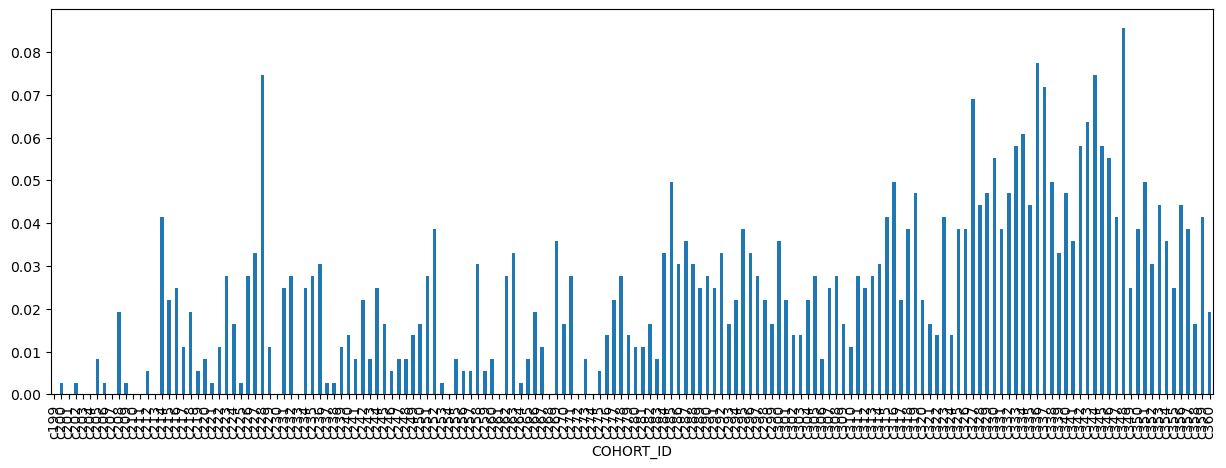

In [97]:
cohort_df.iloc[200:]['SutureOpenRatio'].plot.bar(figsize=(15,5))

In [49]:
db_df.groupby('COHORT_ID')['SutureOpen'].sum()

COHORT_ID
c001     0
c002     0
c003     0
c004     0
c005     0
        ..
c353    16
c354    13
c355     9
c356    16
c357    14
Name: SutureOpen, Length: 359, dtype: int64

<AxesSubplot: xlabel='STRAIN'>

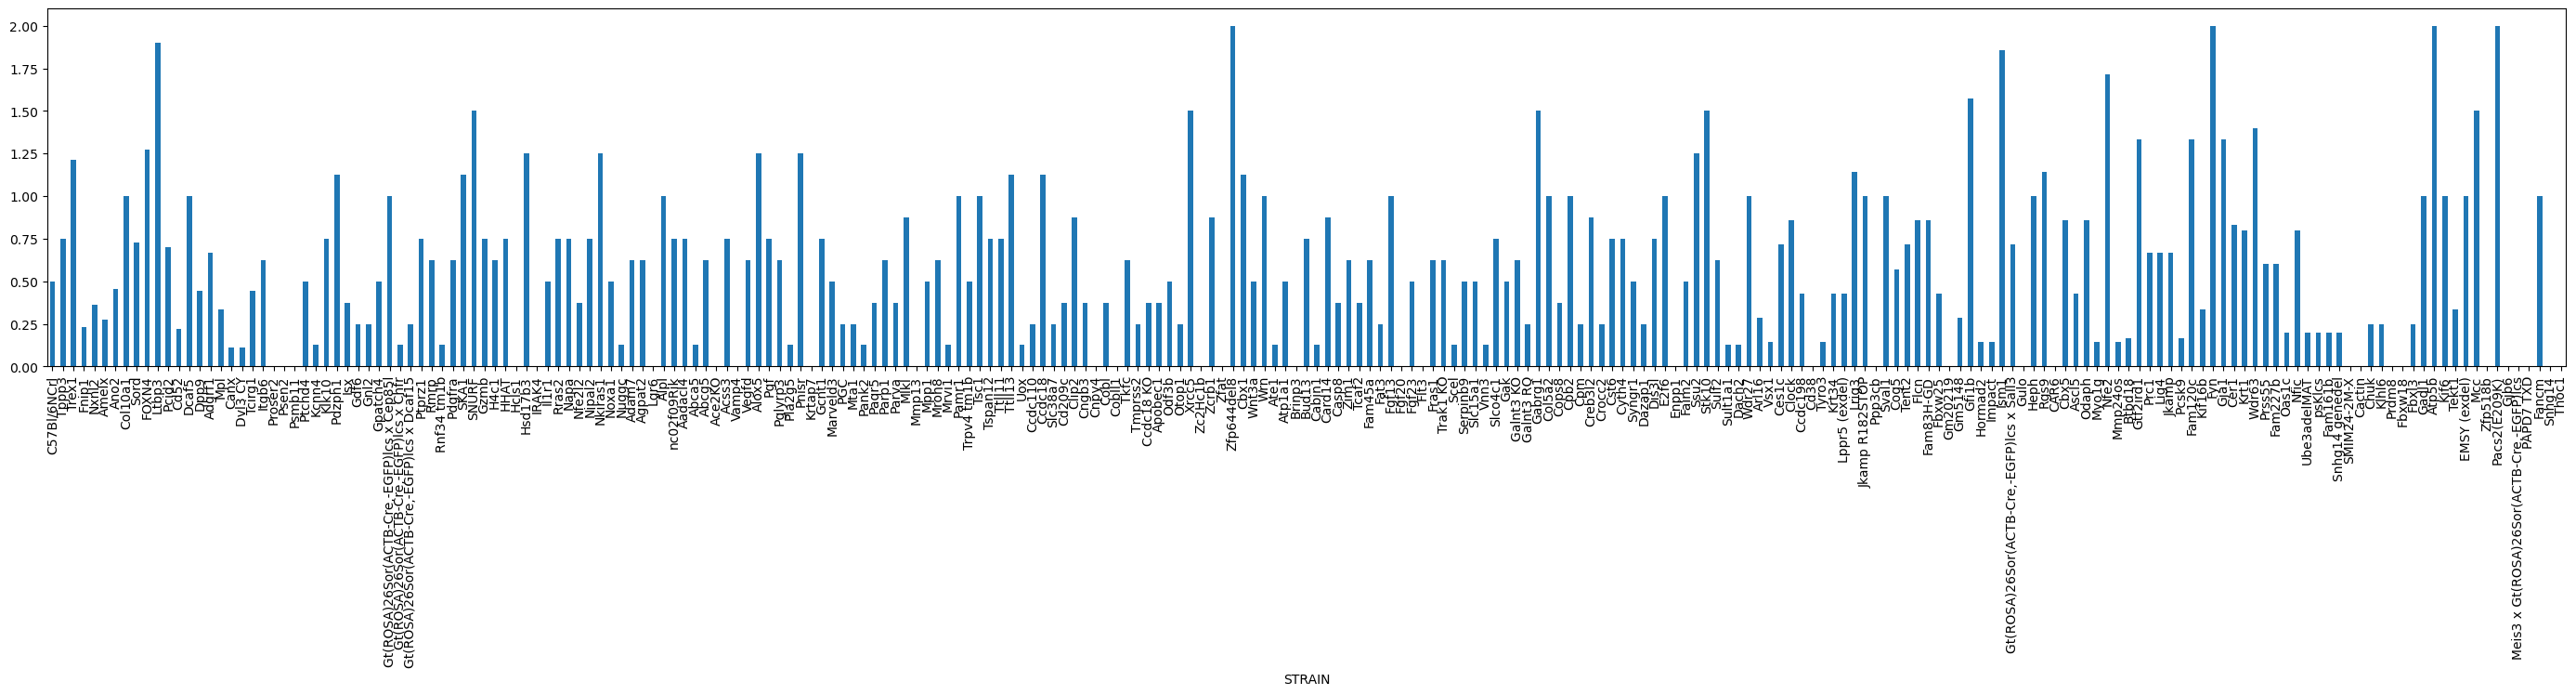

In [104]:
# analyse ratio of SutureOpen in each strain after cohort id > 200
strain_df = db_df[db_df['COHORT_ID'] > 'c200']
strain_df = strain_df[strain_df['GENDER'] == 'female']
strain_df = strain_df.groupby('STRAIN').count()

strain_df = strain_df.sort_values('COHORT_ID',ascending=False)

strain_df['SutureOpen'] = db_df[db_df['COHORT_ID'] > 'c200'].groupby('STRAIN')['SutureOpen'].sum()
strain_df['SutureOpenRatio'] = strain_df['SutureOpen']/strain_df['COHORT_ID']
strain_df['SutureOpenRatio'].plot.bar(figsize=(35,5))

#sort by strainsize
strain_df['SutureOpenRatio'].plot.bar(figsize=(35,5))

In [105]:
strain_df

,SPECIMEN_ID,GENDER,COHORT_ID,DATE,SkullShape,CraniumLength,Comment,SutureOpen,SutureOpenRatio
STRAIN,,,,,,,,,
C57Bl/6NCrl,836,836,836,836,836,800,632,416,0.497608
Tppp3,16,16,16,16,16,16,15,12,0.750000
Trex1,14,14,14,14,14,14,14,17,1.214286
Fnip1,13,13,13,13,13,13,7,3,0.230769
Nxnl2,11,11,11,11,11,11,9,4,0.363636
...,...,...,...,...,...,...,...,...,...
"Meis3 x Gt(ROSA)26Sor(ACTB-Cre,-EGFP)lcs",1,1,1,1,1,1,0,0,0.000000
PAPD7 TXD,1,1,1,1,1,1,1,0,0.000000
Fancm,1,1,1,1,1,1,1,1,1.000000


In [52]:
db_df.groupby('STRAIN')['SutureOpen'].sum()

STRAIN
(Gt(ROSA)26Sor(ACTB-Cre,-EGFP)lcs x C57BL/6N-A<tm1Brd>/a Rnft2<tm1a(EUCOMM)Hmgu>/BcmMmucd) x Rnft1     0
0610009O20Rik (del)                                                                                    0
0610040J01Rik                                                                                          0
1700026D08Rik (indel)                                                                                  0
1810011H11Rik(indel)                                                                                   1
                                                                                                      ..
ncGm15551                                                                                              4
psKlcs                                                                                                 1
rDsg-4                                                                                                 1
rGunn                                           

In [53]:
strain_df

,SPECIMEN_ID,GENDER,COHORT_ID,DATE,SkullShape,CraniumLength,Comment,SutureOpen,SutureOpenRatio
STRAIN,,,,,,,,,
C57Bl/6NCrl,1615,1615,1615,1615,1615,1547,1190,402,0.248916
Ano2,29,29,29,29,29,29,18,5,0.172414
Tppp3,29,29,29,29,29,27,24,12,0.413793
Trex1,27,27,27,27,27,27,27,17,0.629630
Nxnl2,25,25,25,25,25,25,17,4,0.160000
...,...,...,...,...,...,...,...,...,...
Calb1,2,2,2,2,2,2,1,0,0.000000
Zc3h8,2,2,2,2,2,2,2,0,0.000000
Atp5b,2,2,2,2,2,2,2,2,1.000000


<AxesSubplot: xlabel='STRAIN,GENDER'>

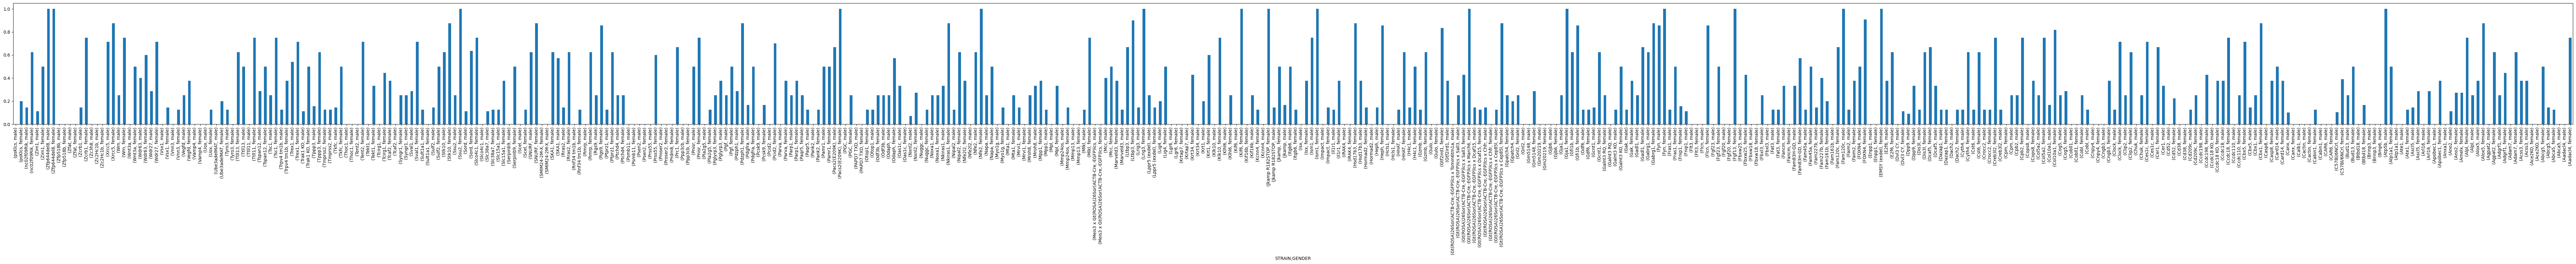

In [81]:
# group by strain and gender
strain_df = 
strain_df = db_df[db_df['COHORT_ID'] > 'c200'].groupby(['STRAIN','GENDER']).count()
strain_df = strain_df.sort_values('STRAIN',ascending=False) 

strain_df['SutureOpen'] = db_df[db_df['COHORT_ID'] > 'c200'].groupby(['STRAIN','GENDER'])['SutureOpen'].sum() 
strain_df['SutureOpenRatio'] = strain_df['SutureOpen']/strain_df['COHORT_ID']
strain_df['SutureOpenRatio'].plot.bar(figsize=(105,5))

<AxesSubplot: xlabel='STRAIN'>

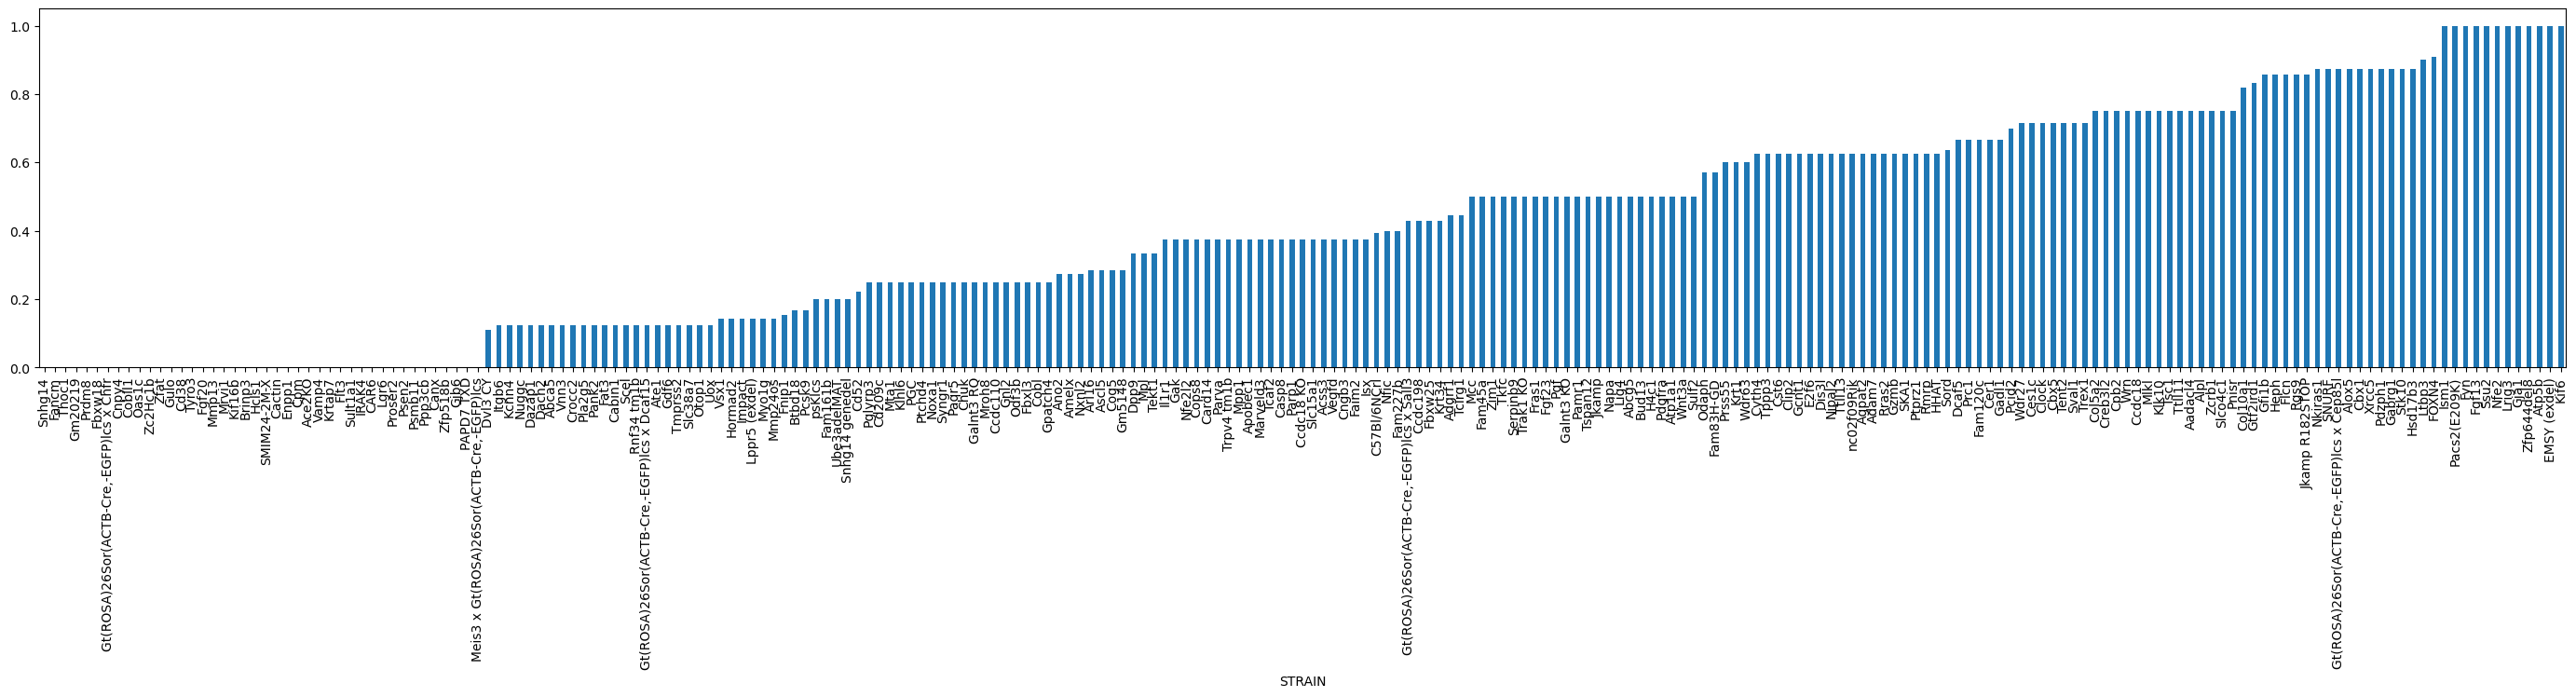

In [111]:
# group by strain (select just females) and check which cohorts have the lowest suture open ratio
# group by strain (select just females) and check which cohorts have the lowest suture open ratio
strain_df = db_df[db_df['COHORT_ID'] > 'c200']
strain_df = strain_df[ strain_df['GENDER'] == 'female']

tmp_cp = strain_df.copy()
strain_df = strain_df.groupby('STRAIN').count()
strain_df = strain_df.sort_values('COHORT_ID',ascending=False)

strain_df['SutureOpen'] = tmp_cp.groupby('STRAIN')['SutureOpen'].sum()
strain_df['SutureOpenRatio'] = strain_df['SutureOpen']/strain_df['COHORT_ID']
#strain_df['SutureOpenRatio'].plot.bar(figsize=(35,5))

# sort by SutureOpenRatio in descending order
strain_df.sort_values('SutureOpenRatio',ascending=True)['SutureOpenRatio'].plot.bar(figsize=(35,5))



In [113]:
strain_df[strain_df['SutureOpenRatio'] == 0]

,SPECIMEN_ID,GENDER,COHORT_ID,DATE,SkullShape,CraniumLength,Comment,SutureOpen,SutureOpenRatio
STRAIN,,,,,,,,,
Canx,9,9,9,9,9,1,7,0,0.0
Proser2,8,8,8,8,8,8,1,0,0.0
Psen2,8,8,8,8,8,8,1,0,0.0
Psmb11,8,8,8,8,8,8,6,0,0.0
"Gt(ROSA)26Sor(ACTB-Cre,-EGFP)lcs x Chfr",8,8,8,8,8,8,3,0,0.0
Hcls1,8,8,8,8,8,8,6,0,0.0
IRAK4,8,8,8,8,8,8,8,0,0.0
Lgr6,8,8,8,8,8,0,5,0,0.0
Ace2KO,8,8,8,8,8,8,1,0,0.0


In [57]:
strain_df.iloc[:20]

SPECIMEN_ID  COHORT_ID  DATE  SkullShape  CraniumLength  \
STRAIN      GENDER                                                            
C57Bl/6NCrl female          821        821   821         821            785   
            male            794        794   794         794            762   
Ano2        male             18         18    18          18             18   
Tppp3       female           16         16    16          16             16   
Ltbp3       male             15         15    15          15             15   
Nxnl2       male             14         14    14          14             14   
Trex1       female           14         14    14          14             14   
Gm5148      male             13         13    13          13             13   
Tppp3       male             13         13    13          13             11   
Trex1       male             13         13    13          13             13   
Fnip1       female           13         13    13          13             13   
Col10a1     male             12         12    12          12             12   
Amelx       female           11         11    11          11             11   
Ano2        female           11         11    11          11             11   
Sord        female           11         11    11          11             11   
Col10a1     female           11         11    11          11             11   
Dpp9        male             11         11    11          11             11   
Nxnl2       female           11         11    11          11             11   
FOXN4       female           11         11    11          11             11   
Gpatch4     male             10         10    10          10             10   

                    Comment  SutureOpen  SutureOpenRatio  
STRAIN      GENDER                                        
C57Bl/6NCrl female      619         320         0.389769  
            male        571          82         0.103275  
Ano2        male         10           2         0.111111  
Tppp3       female       15          10         0.625000  
Ltbp3       male         14          10         0.666667  
Nxnl2       male          8           1         0.071429  
Trex1       female       14          10         0.714286  
Gm5148      male          9           0         0.000000  
Tppp3       male          9           2         0.153846  
Trex1       male         13           7         0.538462  
Fnip1       female        7           2         0.153846  
Col10a1     male         12           2         0.166667  
Amelx       female       10           3         0.272727  
Ano2        female        8           3         0.272727  
Sord        female       11           7         0.636364  
Col10a1     female       10           9         0.818182  
Dpp9        male          4           1         0.090909  
Nxnl2       female        9           3         0.272727  
FOXN4       female       11          10         0.909091  
Gpatch4     male          9           2         0.200000

In [45]:
t1 = db_df[db_df['STRAIN'] == 'Gfi1b']
t1.drop_duplicates()

,SPECIMEN_ID,STRAIN,GENDER,COHORT_ID,DATE,SkullShape,CraniumLength,Comment,SutureOpen
6329,E64-CJ826,Gfi1b,male,c348,2024-07-22,abnormal,27.66,"T1 not fused, scoliotic, pectus excavatum, cra...",True
6337,E64-CJ827,Gfi1b,male,c348,2024-07-22,abnormal,28.15,"T1 not fused, pectus excavatum, cranial suture...",True
6345,E64-CJ829,Gfi1b,female,c348,2024-07-22,abnormal,26.64,cranial sutures open,True
6353,E64-CJ836,Gfi1b,female,c349,2024-07-29,normal,25.60,"T1 not fused, tail cut off (caudal v. 25), kyp...",False
6354,E64-CJ837,Gfi1b,female,c349,2024-07-29,abnormal,26.78,cranial sutures open,True
6355,E64-CJ839,Gfi1b,male,c348,2024-07-22,abnormal,26.78,"tail tip cut off (24 caudal v.), cranial sutur...",True
6363,E64-CJ842,Gfi1b,male,c348,2024-07-22,abnormal,26.56,"T1 not fused, cranial sutures open",True
6371,E64-CJ843,Gfi1b,female,c348,2024-07-22,abnormal,25.83,cranial sutures open mild,True
6379,E64-CJ844,Gfi1b,female,c348,2024-07-22,abnormal,26.07,"T1 not fused, pectus excavatum mild, cranial s...",True
6387,E64-CJ849,Gfi1b,male,c348,2024-07-22,abnormal,26.94,"pectus excavatum mild, cranial sutures open",True


<AxesSubplot: xlabel='COHORT_ID'>

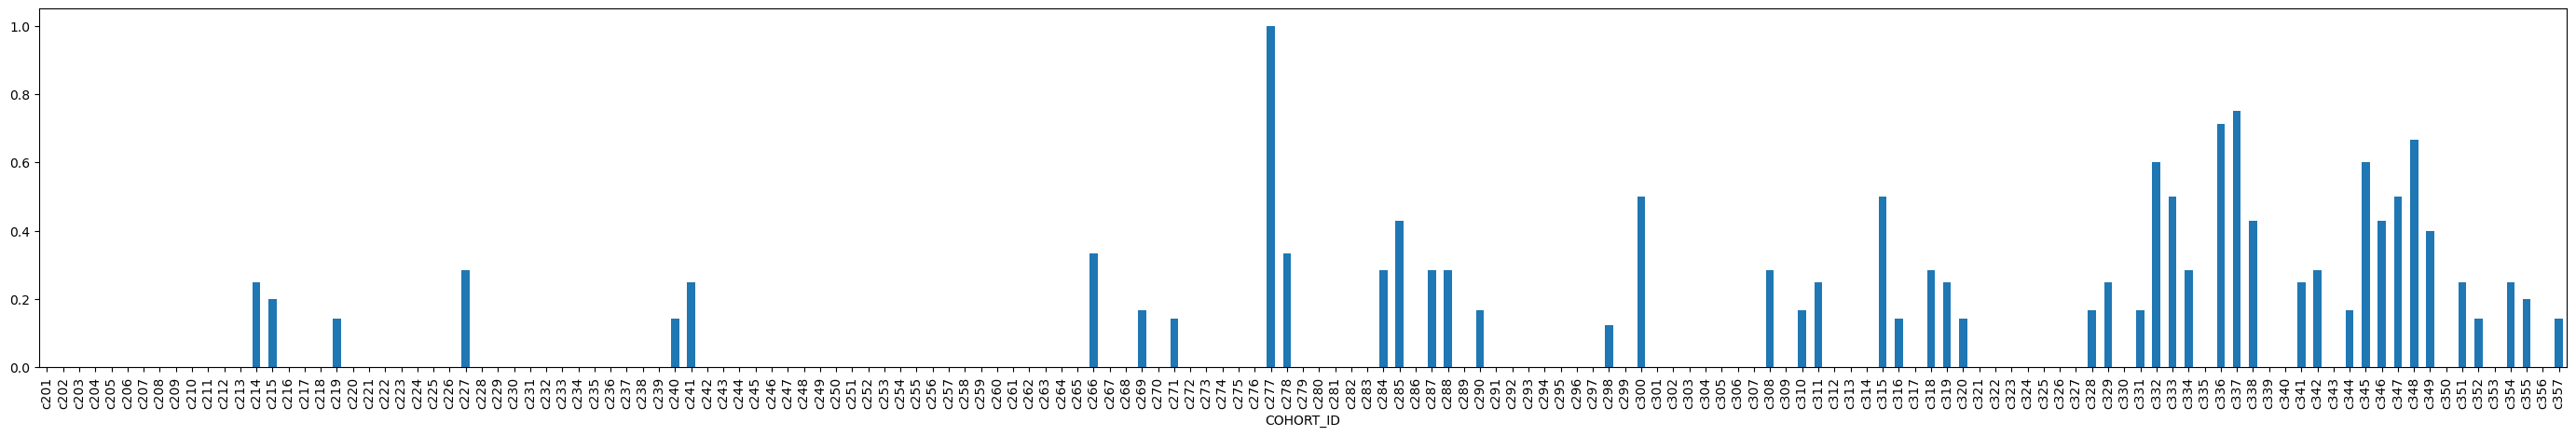

In [76]:

t1 = (db_df[db_df['STRAIN'] == 'C57Bl/6NCrl'])

t1 = t1[t1['COHORT_ID'] > 'c200']
# plot suture open ratio per cohort
# females 
t1 = t1[t1['GENDER']=='male']
test = t1.groupby('COHORT_ID').count()
test['SutureOpen'] = t1.groupby('COHORT_ID')['SutureOpen'].sum()
test['SutureOpenRatio'] = test['SutureOpen']/test['SPECIMEN_ID']
test['SutureOpenRatio'].plot.bar(figsize=(35,5))

<AxesSubplot: xlabel='COHORT_ID'>

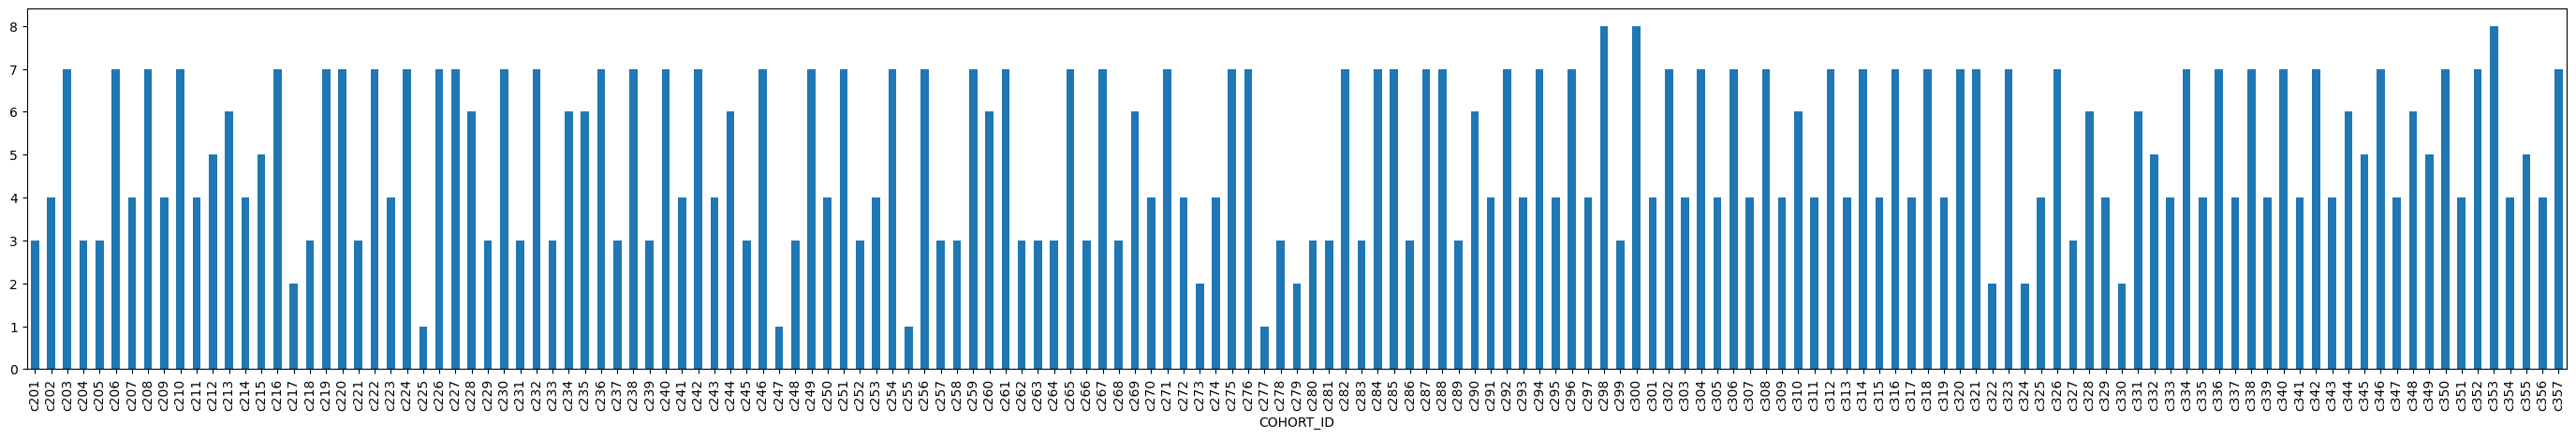

In [77]:
test['GENDER'].plot.bar(figsize=(35,5))

,STRAIN,COHORT_ID,SutureOpen,Count,SutureOpenRatio
0,Zfat,c201,0,8,0.0
1,Zc2Hc1b,c221,0,8,0.0
2,Vamp4,c206,0,8,0.0
3,Brinp3,c233,0,8,0.0
4,Krtap7,c201,0,8,0.0
...,...,...,...,...,...
234,Atp5b,c359,3,3,1.0
235,Nfe2,c336,7,7,1.0
236,Ism1,c294,7,7,1.0
237,Lrig3,c218,7,7,1.0


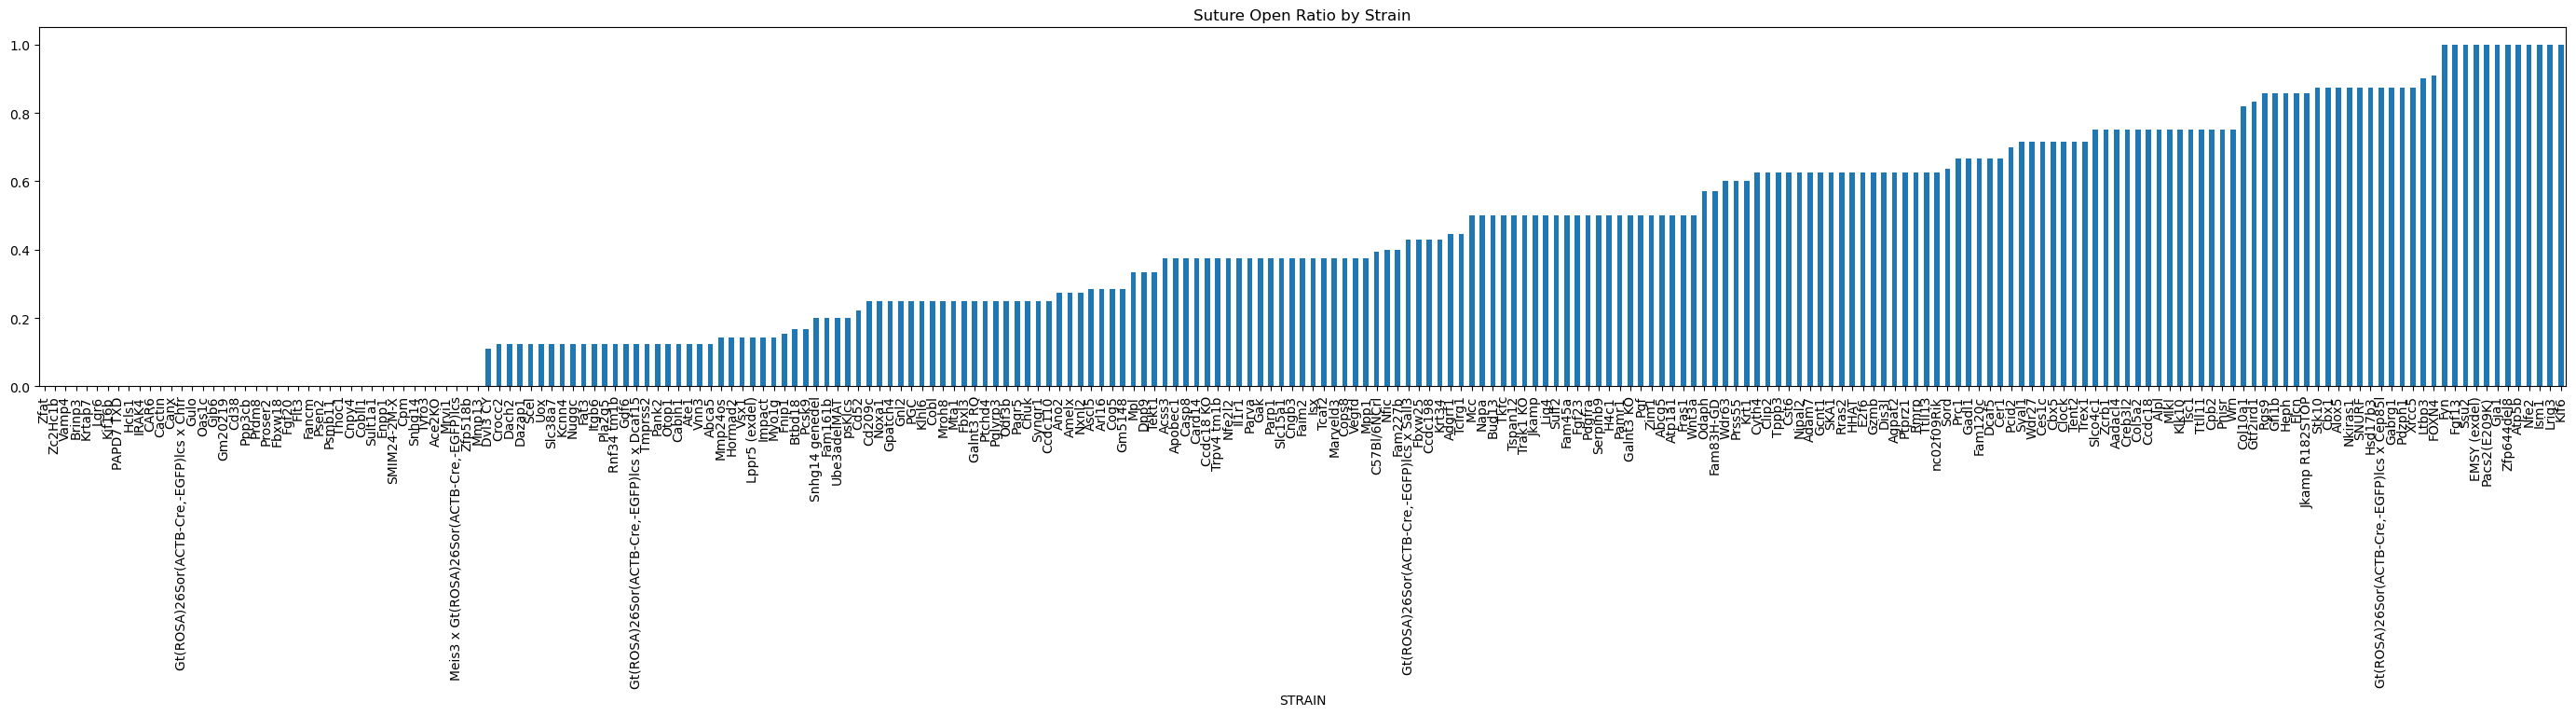

In [114]:
# Filter for cohorts with ID > 'c200' and females only
strain_df = db_df[db_df['COHORT_ID'] > 'c200']
strain_df = strain_df[strain_df['GENDER'] == 'female']

# Make a copy for calculations
tmp_cp = strain_df.copy()

# Group by STRAIN and aggregate
strain_summary = strain_df.groupby('STRAIN').agg({
    'COHORT_ID': 'first',  # Assuming one COHORT_ID per strain
    'SutureOpen': 'sum',   # Sum of SutureOpen per strain
    'GENDER': 'count'      # Count number of entries (used for ratio calculation)
}).rename(columns={'GENDER': 'Count'})

# Calculate SutureOpenRatio
strain_summary['SutureOpenRatio'] = strain_summary['SutureOpen'] / strain_summary['Count']

# Sort by SutureOpenRatio in ascending order
strain_summary = strain_summary.sort_values('SutureOpenRatio', ascending=True)

# Plot SutureOpenRatio
strain_summary['SutureOpenRatio'].plot.bar(figsize=(35, 5), title='Suture Open Ratio by Strain')

# Display the result
strain_summary.reset_index(inplace=True)
strain_summary

In [121]:
strain_summary[
    (strain_summary['SutureOpenRatio'] < 0.2) & (strain_summary['Count'] >= 5)
]


,STRAIN,COHORT_ID,SutureOpen,Count,SutureOpenRatio
0,Zfat,c201,0,8,0.000000
1,Zc2Hc1b,c221,0,8,0.000000
2,Vamp4,c206,0,8,0.000000
3,Brinp3,c233,0,8,0.000000
4,Krtap7,c201,0,8,0.000000
...,...,...,...,...,...
68,Impact,c273,1,7,0.142857
69,Myo1g,c231,1,7,0.142857
70,Fnip1,c206,2,13,0.153846
71,Btbd18,c240,1,6,0.166667
